# EcoPrompt: An Energy- and Cost-Aware Adaptive Prompt Engineering Framework
**ICT Express - Full Paper Code (Local Model + Kaggle GPU + Batch Inference)**

This notebook fixes four issues found in review:
1. **Robust answer extraction** - long chain-of-thought outputs (BoolQ yes/no) are now parsed correctly.
2. **Fair energy accounting** - EcoPrompt is batched like the baselines (no single-query penalty).
3. **Honest baselines** - EcoPrompt is compared against the best cheap baseline and against Always-CoT.
4. **Router ablation** - learned vs random vs always-cheapest vs always-CoT routing is measured.

See the energy-model cell for the explicit assumptions.

## Cell 1: Install Dependencies

In [4]:
!pip install -q transformers torch datasets scikit-learn pandas matplotlib seaborn tqdm

## Cell 2: Imports and Configuration

In [5]:
import os, re, json, time, random
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from collections import Counter
from tqdm import tqdm

import torch
from transformers import AutoTokenizer, AutoModelForCausalLM
from datasets import load_dataset
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score, f1_score, classification_report

SEED = 42
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)

DEVICE = 'cuda' if torch.cuda.is_available() else 'cpu'
print(f'Device: {DEVICE}')

MODEL_NAME = 'Qwen/Qwen2.5-1.5B-Instruct'
MAX_NEW_TOKENS = 128
NUM_SAMPLES = 300
BATCH_SIZE = 8

# ---- Energy / cost model parameters ----
ELECTRICITY_PRICE_PER_KWH = 0.15   # USD per kWh (average US grid price)
CPU_TDP_W = 65                     # CPU overhead for tokenization + data loading
RAM_W = 10                         # RAM overhead

if DEVICE == 'cuda':
    GPU_NAME = torch.cuda.get_device_name(0)
    TDP_MAP = {'T4': 70, 'P100': 250, 'V100': 300, 'A100': 400,
               'H100': 700, 'L4': 72, 'A10': 150, 'K80': 149,
               '3090': 350, '4090': 450}
    GPU_TDP_W = next((v for k, v in TDP_MAP.items() if k.lower() in GPU_NAME.lower()), 400)
else:
    GPU_NAME = 'CPU'
    GPU_TDP_W = 0

TOTAL_POWER_W = GPU_TDP_W + CPU_TDP_W + RAM_W
print(f'GPU: {GPU_NAME} (TDP {GPU_TDP_W} W) | Total power model: {TOTAL_POWER_W} W')
print(f'Model: {MODEL_NAME}, Samples: {NUM_SAMPLES}, Batch: {BATCH_SIZE}')

RESULTS_DIR = '/kaggle/working/results'
os.makedirs(RESULTS_DIR, exist_ok=True)


def estimate_energy_kwh(seconds):
    return TOTAL_POWER_W * seconds / 3600.0 / 1000.0


def estimate_cost_usd(kwh):
    return kwh * ELECTRICITY_PRICE_PER_KWH

Device: cuda
GPU: Tesla T4 (TDP 70 W) | Total power model: 145 W
Model: Qwen/Qwen2.5-1.5B-Instruct, Samples: 300, Batch: 8


## Cell 3: Energy Model (documented assumptions)
Energy is estimated from **measured wall-clock latency** and a documented power model:

- **GPU**: name-specific TDP (A100=400 W, H100=700 W, T4=70 W, ...). Assumes the GPU draws its TDP while generating.
- **CPU + RAM**: fixed 65 W + 10 W overhead for tokenization and data loading.
- `Energy (kWh) = Power (W) x Time (h) / 1000`
- `Cost (USD) = Energy (kWh) x $0.15/kWh`

This is a **model-based estimate**, not a plug-level measurement. All methods use the **same batch size**, so the comparison is fair. Validate against `codecarbon` or a power meter before publication.

## Cell 4: Load Model

In [6]:
tokenizer = AutoTokenizer.from_pretrained(MODEL_NAME)
if tokenizer.pad_token is None:
    tokenizer.pad_token = tokenizer.eos_token
tokenizer.padding_side = 'left'
model = AutoModelForCausalLM.from_pretrained(
    MODEL_NAME,
    torch_dtype=torch.float16 if DEVICE == 'cuda' else torch.float32,
    device_map='auto' if DEVICE == 'cuda' else None
)
model.eval()
print('Model ready')

Loading weights:   0%|          | 0/338 [00:00<?, ?it/s]

Model ready


## Cell 5: Fixed Prompt Templates

In [7]:
PROMPTS = {
    'P0': '{q}\nAnswer:',
    'P1': '{q}\nGive a short, direct answer.\nAnswer:',
    'P2': '{q}\nAnswer:',  # few-shot is assembled in make_prompt
    'P3': '{q}\nGive a short reason, then give the final answer.\nAnswer:',
    'P5': '{q}\nAnswer in one word.\nAnswer:'
}

FEWSHOT_EXAMPLES = {
    'classification': {
        'q': 'Classify sentiment (positive/negative): This movie is wonderful',
        'a': 'positive'
    },
    'factual_qa': {
        'q': 'Passage: The Pacific Ocean is the largest ocean on Earth.\nQuestion: Is the Pacific Ocean the largest ocean?\nAnswer yes or no.',
        'a': 'yes'
    },
    'reasoning': {
        'q': 'Which planet is known as the Red Planet?\nA: Venus\nB: Mars\nC: Jupiter\nD: Saturn\nAnswer with the letter.',
        'a': 'B'
    }
}

def make_prompt(q, strategy, task='classification', example=None):
    if strategy == 'P2':
        ex = example if example is not None else FEWSHOT_EXAMPLES.get(task)
        if ex is None:
            return f'{q}\nAnswer:'
        return f"Example:\n{ex['q']}\nAnswer: {ex['a']}\n\n{q}\nAnswer:"
    return PROMPTS[strategy].replace('{q}', q)

print('Templates ready')

Templates ready


## Cell 6: Answer Extraction (robust) + Batched Inference
`extract` now searches the whole response for the final answer instead of only the last line, which is required for long chain-of-thought outputs.

In [8]:

def extract(response, task):
    r = response.strip()
    lines = [l.strip() for l in r.split('\n') if l.strip()]
    last = lines[-1].lower() if lines else r.lower()

    if task == 'classification':
        m = re.search(r'answer\s*(?:is|:|=)?\s*(positive|negative)\b', r.lower())
        if m:
            return '1' if m.group(1) == 'positive' else '0'
        toks = re.findall(r'\b(positive|negative)\b', r.lower())
        if toks:
            return '1' if toks[-1] == 'positive' else '0'
        for w in last.split():
            if 'pos' in w: return '1'
            if 'neg' in w: return '0'
    elif task == 'factual_qa':
        m = re.search(r'answer\s*(?:is|:|=)?\s*(yes|no)\b', r.lower())
        if m:
            return m.group(1)
        toks = re.findall(r'\b(yes|no)\b', r.lower())
        if toks:
            return toks[-1]
        for w in last.split():
            if 'yes' in w: return 'yes'
            if 'no' in w: return 'no'
    elif task == 'reasoning':
        m = re.search(r'answer\s*(?:is|:|=)?\s*\(?([A-E])\)?', r.upper())
        if m: return m.group(1)
        m = re.findall(r'\b([A-E])\b', r.upper())
        if m: return m[-1]
    elif task == 'math':
        nums = re.findall(r'-?\d+\.?\d*', r.replace(',', ''))
        if nums: return nums[-1]
    return last


def batch_inference(prompts, max_tokens=MAX_NEW_TOKENS):
    """Batched greedy generation. Also returns the mean log-probability of the
    generated tokens, which is used as a per-query confidence signal."""
    messages_list = [[{'role': 'user', 'content': p}] for p in prompts]
    texts = [tokenizer.apply_chat_template(m, tokenize=False, add_generation_prompt=True) for m in messages_list]
    inputs = tokenizer(texts, return_tensors='pt', padding=True, truncation=True, max_length=2048)
    if DEVICE == 'cuda':
        inputs = {k: v.to(DEVICE) for k, v in inputs.items()}
    prompt_tokens_per_sample = inputs['attention_mask'].sum(dim=1).tolist()
    start = time.time()
    with torch.no_grad():
        outputs = model.generate(
            **inputs,
            max_new_tokens=max_tokens,
            do_sample=False,
            pad_token_id=tokenizer.pad_token_id,
            eos_token_id=tokenizer.eos_token_id,
            return_dict_in_generate=True,
            output_scores=True
        )
    latency = time.time() - start
    input_len = inputs['input_ids'].shape[1]
    gen = outputs.sequences[:, input_len:]
    responses = [tokenizer.decode(seq, skip_special_tokens=True).strip() for seq in gen]
    resp_tokens_per_sample = (gen != tokenizer.pad_token_id).sum(dim=1).tolist()
    mean_logprob = [float('nan')] * len(prompts)
    if getattr(outputs, 'scores', None) is not None:
        mask = (gen != tokenizer.pad_token_id).float()
        lp_steps = []
        for step in range(gen.shape[1]):
            logits = outputs.scores[step].float()
            lp = torch.log_softmax(logits, dim=-1)
            tok = gen[:, step]
            lp_steps.append(lp.gather(1, tok.unsqueeze(1)).squeeze(1))
        lp_stack = torch.stack(lp_steps, dim=1)
        denom = mask.sum(dim=1).clamp(min=1)
        mean_logprob = ((lp_stack * mask).sum(dim=1) / denom).tolist()
    return responses, prompt_tokens_per_sample, resp_tokens_per_sample, latency, mean_logprob


def run_batched_strategy(examples, strategy, task):
    """Run a fixed strategy over a list of examples in batches (same batching as baselines)."""
    responses, prompt_tokens, response_tokens, latencies, logprobs = [], [], [], [], []
    for i in range(0, len(examples), BATCH_SIZE):
        batch = examples[i:i + BATCH_SIZE]
        prompts = [make_prompt(ex['q'], strategy, task) for ex in batch]
        resps, pt, rt, lat, lp = batch_inference(prompts)
        responses.extend(resps)
        prompt_tokens.extend(pt)
        response_tokens.extend(rt)
        latencies.append(lat)
        logprobs.extend(lp)
    return responses, prompt_tokens, response_tokens, latencies, logprobs


print('Functions ready')


Functions ready


## Cell 7: Load + Format Data

In [9]:
print('Loading datasets...')
sst2_raw = load_dataset('nyu-mll/glue', 'sst2')
boolq_raw = load_dataset('google/boolq')
arc_raw = load_dataset('allenai/ai2_arc', 'ARC-Easy')

def sample(ds, n=NUM_SAMPLES, seed=SEED):
    rng = np.random.RandomState(seed)
    idx = rng.choice(len(ds), size=min(n, len(ds)), replace=False)
    return ds[idx.tolist()]

def fmt_sst2(d):
    return [{'q': f'Classify sentiment (positive/negative): {s}', 'a': str(l), 'task': 'classification'} for s, l in zip(d['sentence'], d['label'])]

def fmt_boolq(d):
    return [{'q': f"{p}\nQuestion: {q}\nAnswer yes or no.", 'a': 'yes' if a else 'no', 'task': 'factual_qa'} for p, q, a in zip(d['passage'], d['question'], d['answer'])]

def fmt_arc(d):
    out = []
    for q, c, k in zip(d['question'], d['choices'], d['answerKey']):
        labels = ['A','B','C','D','E'][:len(c['text'])]
        opts = '\n'.join([f'{l}: {t}' for l, t in zip(labels, c['text'])])
        a = labels[int(k)-1] if k.isdigit() else k
        out.append({'q': f"{q}\n{opts}\nAnswer with the letter.", 'a': a, 'task': 'reasoning'})
    return out

data = {
    'SST-2': fmt_sst2(sample(sst2_raw['validation'])),
    'BoolQ': fmt_boolq(sample(boolq_raw['validation'])),
    'ARC': fmt_arc(sample(arc_raw['test']))
}

for name, d in data.items():
    print(f'{name}: {len(d)} samples')
print('Sample BoolQ:', data['BoolQ'][0])

Loading datasets...


README.md:   0%|          | 0.00/35.3k [00:00<?, ?B/s]

sst2/train-00000-of-00001.parquet: reconstructing file:   0%|          |  0.00B / 3.11MB            

sst2/train-00000-of-00001.parquet: downloading bytes:           |  0.00B            

sst2/validation-00000-of-00001.parquet: reconstructing file:   0%|          |  0.00B / 72.8kB            

...

ARC-Easy/validation-00000-of-00001.parqu(…): downloading bytes:           |  0.00B            

Generating train split:   0%|          | 0/2251 [00:00<?, ? examples/s]

Generating test split:   0%|          | 0/2376 [00:00<?, ? examples/s]

Generating validation split:   0%|          | 0/570 [00:00<?, ? examples/s]

SST-2: 300 samples
BoolQ: 300 samples
ARC: 300 samples
Sample BoolQ: {'q': "Travel to each of these altitude regions can lead to medical problems, from the mild symptoms of acute mountain sickness to the potentially fatal high-altitude pulmonary edema (HAPE) and high-altitude cerebral edema (HACE). The higher the altitude, the greater the risk. Research also indicates elevated risk of permanent brain damage in people climbing to extreme altitudes. Expedition doctors commonly stock a supply of dexamethasone, or ``dex,'' to treat these conditions on site.\nQuestion: is living at high altitude good for you\nAnswer yes or no.", 'a': 'no', 'task': 'factual_qa'}


## Cell 8: Debug (Run First!)

In [10]:

print('=== BoolQ P0 vs P3 ===')
for strat in ['P0', 'P3']:
    for i in range(3):
        ex = data['BoolQ'][i]
        p = make_prompt(ex['q'], strat)
        r, _, _, _, _ = batch_inference([p])
        print(f"[{strat}] Gold: {ex['a']} | Extracted: {repr(extract(r[0], 'factual_qa'))}")
    print('---')

print('=== SST-2 ===')
for i in range(3):
    ex = data['SST-2'][i]
    p = make_prompt(ex['q'], 'P0')
    r, _, _, _, _ = batch_inference([p])
    print(f"Gold: {ex['a']} | Extracted: {repr(extract(r[0], 'classification'))}")
    print('---')


=== BoolQ P0 vs P3 ===
[P0] Gold: no | Extracted: 'no'
[P0] Gold: no | Extracted: 'yes'
[P0] Gold: no | Extracted: 'no'
---
[P3] Gold: no | Extracted: 'no'
[P3] Gold: no | Extracted: 'no'
[P3] Gold: no | Extracted: 'no'
---
=== SST-2 ===
Gold: 1 | Extracted: '1'
---
Gold: 0 | Extracted: '0'
---
Gold: 0 | Extracted: '0'
---


## Cell 9: Run Fixed Baselines (Batch)

In [11]:

baseline_strategies = ['P0', 'P1', 'P2', 'P3', 'P5']
baseline_results = {}
baseline_predictions = {}
baseline_responses = {}
baseline_logprobs = {}
baseline_sample_latency = {}

for task_name, examples in data.items():
    print(f'\n{"="*50}')
    print(f'Task: {task_name}')
    print(f'{"="*50}')
    baseline_results[task_name] = {}
    baseline_predictions[task_name] = {}
    baseline_responses[task_name] = {}
    baseline_logprobs[task_name] = {}
    baseline_sample_latency[task_name] = {}

    for strategy in baseline_strategies:
        print(f'  Running {strategy}...')
        responses, prompt_tokens, response_tokens, latencies, logprobs = run_batched_strategy(examples, strategy, examples[0]['task'])
        predictions = [extract(resp, examples[0]['task']) for resp in responses]
        golds = [ex['a'] for ex in examples]
        correct = [int(p == g) for p, g in zip(predictions, golds)]
        acc = float(np.mean(correct))
        f1 = f1_score(golds, predictions, average='weighted', zero_division=0) if examples[0]['task'] == 'classification' else acc
        total_time = float(np.sum(latencies))
        energy_kwh = estimate_energy_kwh(total_time)
        cost_usd = estimate_cost_usd(energy_kwh)

        sample_lat = []
        for bi, lat in zip(range(0, len(examples), BATCH_SIZE), latencies):
            n = min(BATCH_SIZE, len(examples) - bi)
            sample_lat.extend([lat / n] * n)

        baseline_predictions[task_name][strategy] = predictions
        baseline_responses[task_name][strategy] = responses
        baseline_logprobs[task_name][strategy] = logprobs
        baseline_sample_latency[task_name][strategy] = sample_lat
        baseline_results[task_name][strategy] = {
            'accuracy': acc,
            'f1': f1,
            'avg_prompt_tokens': float(np.mean(prompt_tokens)),
            'avg_response_tokens': float(np.mean(response_tokens)),
            'avg_latency': total_time / len(examples),
            'total_energy_kwh': energy_kwh,
            'total_cost_usd': cost_usd,
            'correct': correct,
            'response_tokens': response_tokens,
        }
        print(f"    Accuracy: {acc:.3f} | F1: {f1:.3f} | Avg Resp Tokens: {np.mean(response_tokens):.1f} | Energy: {energy_kwh:.6f} kWh | Cost: ${cost_usd:.6f}")

print('\nBaseline results complete')



Task: SST-2
  Running P0...
    Accuracy: 0.910 | F1: 0.910 | Avg Resp Tokens: 4.7 | Energy: 0.001797 kWh | Cost: $0.000270
  Running P1...
    Accuracy: 0.907 | F1: 0.906 | Avg Resp Tokens: 2.0 | Energy: 0.000236 kWh | Cost: $0.000035
  Running P2...
    Accuracy: 0.927 | F1: 0.928 | Avg Resp Tokens: 2.0 | Energy: 0.000250 kWh | Cost: $0.000037
  Running P3...
    Accuracy: 0.907 | F1: 0.907 | Avg Resp Tokens: 33.6 | Energy: 0.005365 kWh | Cost: $0.000805
  Running P5...
    Accuracy: 0.897 | F1: 0.898 | Avg Resp Tokens: 2.0 | Energy: 0.000232 kWh | Cost: $0.000035

Task: BoolQ
  Running P0...
    Accuracy: 0.777 | F1: 0.777 | Avg Resp Tokens: 6.1 | Energy: 0.001997 kWh | Cost: $0.000300
  Running P1...
    Accuracy: 0.773 | F1: 0.773 | Avg Resp Tokens: 3.0 | Energy: 0.000652 kWh | Cost: $0.000098
  Running P2...
    Accuracy: 0.753 | F1: 0.753 | Avg Resp Tokens: 2.9 | Energy: 0.000706 kWh | Cost: $0.000106
  Running P3...
    Accuracy: 0.760 | F1: 0.760 | Avg Resp Tokens: 68.3 | Ene

## Cell 10: Save Baselines

In [12]:
with open(f'{RESULTS_DIR}/baseline_results.json', 'w') as f:
    json.dump(baseline_results, f, indent=2)

df_baselines = pd.DataFrame([
    {'Task': task, 'Strategy': strat, 'Accuracy': round(m['accuracy'], 3),
     'Avg Prompt Tokens': round(m['avg_prompt_tokens'], 1),
     'Avg Resp Tokens': round(m['avg_response_tokens'], 1),
     'Avg Latency (s)': round(m['avg_latency'], 3),
     'Energy (kWh)': f"{m['total_energy_kwh']:.6f}",
     'Cost (USD)': f"{m['total_cost_usd']:.6f}"}
    for task, strats in baseline_results.items()
    for strat, m in strats.items()
])
print(df_baselines.to_string(index=False))

 Task Strategy  Accuracy  Avg Prompt Tokens  Avg Resp Tokens  Avg Latency (s) Energy (kWh) Cost (USD)
SST-2       P0     0.910               62.9              4.7            0.149     0.001797   0.000270
SST-2       P1     0.907               69.9              2.0            0.020     0.000236   0.000035
SST-2       P2     0.927               81.9              2.0            0.021     0.000250   0.000037
SST-2       P3     0.907               73.9             33.6            0.444     0.005365   0.000805
SST-2       P5     0.897               67.9              2.0            0.019     0.000232   0.000035
BoolQ       P0     0.777              171.0              6.1            0.165     0.001997   0.000300
BoolQ       P1     0.773              178.0              3.0            0.054     0.000652   0.000098
BoolQ       P2     0.753              205.0              2.9            0.058     0.000706   0.000106
BoolQ       P3     0.760              182.0             68.3            0.709     

## Cell 11: Difficulty Labels + Complexity Features
Each query is labelled **hard** when the task's cheap base strategy answers it wrong. This gives the router a real per-query learning signal instead of memorizing task identity.

In [13]:
CHEAP_STRATEGIES = ['P0', 'P1', 'P2', 'P5']

calib_idx_by_task = {}
test_idx_by_task = {}
for task_name, examples in data.items():
    idx = np.arange(len(examples))
    c, t = train_test_split(idx, test_size=0.4, random_state=SEED)
    calib_idx_by_task[task_name] = sorted(c.tolist())
    test_idx_by_task[task_name] = sorted(t.tolist())


def learn_base_strategy(task_name, examples, calib_idx):
    """Pick the cheap strategy with the best calibration accuracy (energy breaks ties)."""
    golds = [ex['a'] for ex in examples]
    scored = []
    for s in CHEAP_STRATEGIES:
        preds = baseline_predictions[task_name][s]
        acc = float(np.mean([preds[i] == golds[i] for i in calib_idx]))
        energy = float(np.mean([baseline_sample_latency[task_name][s][i] for i in calib_idx]))
        scored.append((s, acc, energy))
    best = max(scored, key=lambda x: (x[1], -x[2]))
    return best[0], scored


BASE_STRATEGY = {}
for task_name, examples in data.items():
    base, scored = learn_base_strategy(task_name, examples, calib_idx_by_task[task_name])
    BASE_STRATEGY[examples[0]['task']] = base
    print(f"{task_name}: base={base} | " + " | ".join(f"{s}: {a:.3f}" for s, a, _ in scored))


def extract_complexity_features(q):
    words = q.split()
    return {
        'token_length': len(words),
        'char_length': len(q),
        'avg_word_length': np.mean([len(w) for w in words]) if words else 0,
        'num_question_marks': q.count('?'),
        'has_numbers': int(any(c.isdigit() for c in q)),
        'has_math_symbols': int(any(c in '+-*/=' for c in q)),
        'num_newlines': q.count('\n'),
        'has_passage': int('\n' in q),
    }

all_questions = []
all_task_names = []
all_tasks = []
all_labels = []
all_base_logprob = []
for task_name, examples in data.items():
    base = BASE_STRATEGY[examples[0]['task']]
    preds = baseline_predictions[task_name][base]
    lps = baseline_logprobs[task_name][base]
    golds = [ex['a'] for ex in examples]
    for ex, p, g, lp in zip(examples, preds, golds, lps):
        all_questions.append(ex['q'])
        all_task_names.append(task_name)
        all_tasks.append(ex['task'])
        all_labels.append(1 if p != g else 0)
        all_base_logprob.append(lp)

feature_rows = [extract_complexity_features(q) for q in all_questions]
df_features = pd.DataFrame(feature_rows)
df_features['base_logprob'] = all_base_logprob
df_features['task_name'] = all_task_names
df_features['task'] = all_tasks
df_features['difficulty_label'] = all_labels
print(f'Extracted features for {len(df_features)} queries')
print(f"Base-strategy error rate (hard=1): {np.mean(all_labels):.3f}")
print(df_features.describe())


SST-2: base=P2 | P0: 0.894 | P1: 0.889 | P2: 0.917 | P5: 0.878
BoolQ: base=P1 | P0: 0.750 | P1: 0.761 | P2: 0.750 | P5: 0.756
ARC: base=P5 | P0: 0.789 | P1: 0.878 | P2: 0.894 | P5: 0.911
Extracted features for 900 queries
Base-strategy error rate (hard=1): 0.132
       token_length  char_length  avg_word_length  num_question_marks  \
count    900.000000   900.000000       900.000000          900.000000   
mean      56.235556   336.496667         5.133497            0.271111   
std       44.679355   267.895363         0.709505            0.444780   
min        7.000000    53.000000         3.703704            0.000000   
25%       25.000000   155.000000         4.659172            0.000000   
50%       40.000000   235.500000         5.025278            0.000000   
75%       74.000000   443.250000         5.441111            1.000000   
max      300.000000  1774.000000         9.500000            1.000000   

       has_numbers  has_math_symbols  num_newlines  has_passage  base_logprob  

## Cell 12: Train Difficulty Classifier

In [14]:
X_all = df_features.drop(['difficulty_label', 'task_name', 'task'], axis=1)
y_all = df_features['difficulty_label']

offset = {}
_o = 0
for task_name in data:
    offset[task_name] = _o
    _o += len(data[task_name])

calib_rows = sorted(offset[t] + i for t in data for i in calib_idx_by_task[t])
test_rows = sorted(offset[t] + i for t in data for i in test_idx_by_task[t])

X_train, y_train = X_all.iloc[calib_rows], y_all.iloc[calib_rows]
X_test, y_test = X_all.iloc[test_rows], y_all.iloc[test_rows]

difficulty_clf = LogisticRegression(max_iter=1000, random_state=SEED, class_weight='balanced')
difficulty_clf.fit(X_train, y_train)
y_pred = difficulty_clf.predict(X_test)
router_accuracy = accuracy_score(y_test, y_pred)
print(f'Difficulty Classifier Accuracy (held-out): {router_accuracy:.3f}')
print(f'  Calibration samples: {len(X_train)} | Test samples: {len(X_test)}')
print(classification_report(y_test, y_pred, target_names=['easy', 'hard'], zero_division=0))


Difficulty Classifier Accuracy (held-out): 0.653
  Calibration samples: 540 | Test samples: 360
              precision    recall  f1-score   support

        easy       0.92      0.66      0.77       315
        hard       0.20      0.60      0.30        45

    accuracy                           0.65       360
   macro avg       0.56      0.63      0.54       360
weighted avg       0.83      0.65      0.71       360



## Cell 13: Routing Policy (learned)

In [15]:
def learn_escalation_targets(data, baseline_predictions, calib_idx_by_task):
    """Learn one escalation target per task on the calibration hard subset.
    Candidates are the cheap strategies plus CoT (P3), which is allowed only as
    an escalation fallback, never as a base. A target is accepted only if it
    fixes at least max(3, 5%) of the calibration hard queries and does not lower
    overall calibration accuracy. Otherwise no escalation is used."""
    targets = {}
    for task_name, examples in data.items():
        task = examples[0]['task']
        base = BASE_STRATEGY[task]
        golds = [ex['a'] for ex in examples]
        base_preds = baseline_predictions[task_name][base]
        calib = calib_idx_by_task[task_name]
        hard_idx = [i for i in calib if base_preds[i] != golds[i]]
        if not hard_idx:
            targets[task] = base
            print(f'  {task_name}: base={base} | no base errors in calibration | target={base}')
            continue
        base_overall = float(np.mean([base_preds[i] == golds[i] for i in calib]))
        min_fixes = max(3, int(np.ceil(0.05 * len(hard_idx))))
        best_strat, best_fixed = base, 0
        for s in CHEAP_STRATEGIES + ['P3']:
            if s == base:
                continue
            preds = baseline_predictions[task_name][s]
            fixed = sum(1 for i in hard_idx if preds[i] == golds[i])
            overall = float(np.mean([preds[i] == golds[i] for i in calib]))
            if fixed >= min_fixes and overall >= base_overall and fixed > best_fixed:
                best_strat, best_fixed = s, fixed
        targets[task] = best_strat
        print(f'  {task_name}: base={base} acc={base_overall:.3f} | hard={len(hard_idx)}/{len(calib)} | '
              f'target={best_strat} (fixes {best_fixed}, needs >= {min_fixes})')
    return targets


ESCALATION_TARGET = learn_escalation_targets(data, baseline_predictions, calib_idx_by_task)


def calibrate_router_threshold(task_name, task, target, budget=0.15, min_gain=0.02):
    """Pick a task-specific probability threshold on the calibration split.
    Escalation must improve calibration accuracy by at least min_gain while
    touching at most `budget` of the queries; otherwise it is disabled."""
    base = BASE_STRATEGY[task]
    if target == base:
        print(f'  {task_name}: target == base -> escalation disabled')
        return float('inf')
    calib = calib_idx_by_task[task_name]
    rows = [offset[task_name] + i for i in calib]
    probs = difficulty_clf.predict_proba(X_all.iloc[rows])[:, 1]
    golds = [ex['a'] for ex in data[task_name]]
    base_preds = baseline_predictions[task_name][base]
    tgt_preds = baseline_predictions[task_name][target]
    base_acc = float(np.mean([base_preds[i] == golds[i] for i in calib]))
    best_tau, best_acc, best_rate = float('inf'), base_acc, 0.0
    for q in np.linspace(0.50, 0.99, 50):
        tau = float(np.quantile(probs, q))
        esc = [i for i, p in zip(calib, probs) if p >= tau]
        if not esc or len(esc) / len(calib) > budget:
            continue
        esc_set = set(esc)
        acc = float(np.mean([(tgt_preds[i] if i in esc_set else base_preds[i]) == golds[i] for i in calib]))
        if acc >= best_acc:
            best_tau, best_acc, best_rate = tau, acc, len(esc) / len(calib)
    if best_acc < base_acc + min_gain:
        print(f'  {task_name}: escalation rejected (best {best_acc:.3f} vs base {base_acc:.3f}, needs +{min_gain:.2f})')
        return float('inf')
    print(f'  {task_name}: tau={best_tau:.4f} | calib {base_acc:.3f}->{best_acc:.3f} | esc {best_rate:.1%}')
    return best_tau


ROUTER_TAU = {
    examples[0]['task']: calibrate_router_threshold(task_name, examples[0]['task'], ESCALATION_TARGET[examples[0]['task']])
    for task_name, examples in data.items()
}


def route_query(q, task, base_logprob):
    """Return (hard, strategy) using the calibrated per-task threshold."""
    features = extract_complexity_features(q)
    features['base_logprob'] = base_logprob
    row = pd.DataFrame([features])[X_all.columns]
    p_hard = float(difficulty_clf.predict_proba(row)[0, 1])
    base = BASE_STRATEGY.get(task, 'P3')
    tau = ROUTER_TAU.get(task, float('inf'))
    hard = int(p_hard >= tau)
    strategy = ESCALATION_TARGET.get(task, base) if hard else base
    return hard, strategy


test_qs = [
    ('Is this sentence positive or negative: I love this movie', 'classification', -0.05),
    ('A ball is thrown upward at 20 m/s. How long to reach max height? g=10', 'reasoning', -0.05),
    ('What is the capital of France?', 'factual_qa', -0.05)
]
for q, t, lp in test_qs:
    h, s = route_query(q, t, lp)
    print(f'  [{t}] hard={h} -> {s}')


  SST-2: base=P2 acc=0.917 | hard=15/180 | target=P2 (fixes 0, needs >= 3)
  BoolQ: base=P1 acc=0.761 | hard=43/180 | target=P3 (fixes 8, needs >= 3)
  ARC: base=P5 acc=0.911 | hard=16/180 | target=P5 (fixes 0, needs >= 3)
  SST-2: target == base -> escalation disabled
  BoolQ: escalation rejected (best 0.767 vs base 0.761, needs +0.02)
  ARC: target == base -> escalation disabled
  [classification] hard=0 -> P2
  [reasoning] hard=0 -> P5
  [factual_qa] hard=0 -> P1


## Cell 14: EcoPrompt - Batched Adaptive Routing
Queries are routed first, then executed **in batches grouped by strategy**, so the energy/latency comparison with the fixed baselines is apples-to-apples. Escalation is handled in rounds.

In [16]:
def run_ecoprompt_reactive(examples, task, task_name, eval_idx):
    """Apply the calibrated router using cached baseline outputs (no new inference)."""
    base = BASE_STRATEGY[task]
    target = ESCALATION_TARGET[task]
    base_lps = baseline_logprobs[task_name][base]

    items = []
    for i in eval_idx:
        ex = examples[i]
        hard, strategy = route_query(ex['q'], task, base_lps[i])
        items.append({
            'i': i, 'ex': ex, 'hard': hard, 'strategy': strategy,
            'base_resp': baseline_responses[task_name][base][i], 'final_resp': None,
            'final_strategy': None, 'escalated': False,
        })

    escalated = [it for it in items if it['strategy'] != base]
    esc_lat = 0.0
    esc_rt = []
    for it in escalated:
        i = it['i']
        it['final_resp'] = baseline_responses[task_name][target][i]
        it['final_rt'] = baseline_results[task_name][target]['response_tokens'][i]
        it['final_strategy'] = target
        it['escalated'] = True
        esc_lat += baseline_sample_latency[task_name][target][i]
        esc_rt.append(it['final_rt'])

    base_rt = baseline_results[task_name][base]['response_tokens']
    for it in items:
        if it['final_resp'] is None:
            it['final_resp'] = baseline_responses[task_name][base][it['i']]
            it['final_rt'] = base_rt[it['i']]
            it['final_strategy'] = base

    return items, esc_lat, esc_rt


def evaluate_reactive(examples, task, task_name, eval_idx):
    items, esc_lat, esc_rt = run_ecoprompt_reactive(examples, task, task_name, eval_idx)
    predictions = [extract(it['final_resp'], task) for it in items]
    golds = [it['ex']['a'] for it in items]
    correct = [int(p == g) for p, g in zip(predictions, golds)]
    acc = float(np.mean(correct)) if correct else 0.0
    base = BASE_STRATEGY[task]
    base_lat = sum(baseline_sample_latency[task_name][base][i] for i in eval_idx)
    total_lat = base_lat + esc_lat
    energy_kwh = estimate_energy_kwh(total_lat)
    cost_usd = estimate_cost_usd(energy_kwh)
    n_esc = sum(1 for it in items if it['escalated'])
    records = [{
        'question': it['ex']['q'], 'gold': it['ex']['a'],
        'prediction': p, 'strategy': it['final_strategy'],
        'escalated': it['escalated'], 'hard': it['hard'],
        'correct': c
    } for it, p, c in zip(items, predictions, correct)]
    metrics = {
        'accuracy': acc,
        'avg_prompt_tokens': float('nan'),
        'avg_response_tokens': float(np.mean([it['final_rt'] for it in items])) if items else 0.0,
        'avg_latency': total_lat / len(eval_idx) if eval_idx else 0.0,
        'escalation_rate': n_esc / len(eval_idx) if eval_idx else 0.0,
        'total_energy_kwh': energy_kwh,
        'total_cost_usd': cost_usd,
        'correct': correct,
    }
    return metrics, records


## Cell 15: Run EcoPrompt (learned router)

In [17]:

ecoprompt_results = {}
ecoprompt_raw = {}

for task_name, examples in data.items():
    print(f'\n{"="*50}')
    print(f'EcoPrompt on: {task_name} (held-out test split)')
    print(f'{"="*50}')
    metrics, records = evaluate_reactive(examples, examples[0]['task'], task_name, test_idx_by_task[task_name])
    ecoprompt_results[task_name] = metrics
    ecoprompt_raw[task_name] = records
    print(f"  Accuracy: {metrics['accuracy']:.3f} | Escalation: {metrics['escalation_rate']:.1%} | Energy: {metrics['total_energy_kwh']:.6f} kWh | Cost: ${metrics['total_cost_usd']:.6f}")

print('\nEcoPrompt complete')



EcoPrompt on: SST-2 (held-out test split)
  Accuracy: 0.942 | Escalation: 0.0% | Energy: 0.000099 kWh | Cost: $0.000015

EcoPrompt on: BoolQ (held-out test split)
  Accuracy: 0.792 | Escalation: 0.0% | Energy: 0.000265 kWh | Cost: $0.000040

EcoPrompt on: ARC (held-out test split)
  Accuracy: 0.892 | Escalation: 0.0% | Energy: 0.000189 kWh | Cost: $0.000028

EcoPrompt complete


## Cell 16: Save EcoPrompt Results

In [18]:

with open(f'{RESULTS_DIR}/ecoprompt_results.json', 'w') as f:
    json.dump(ecoprompt_results, f, indent=2)
with open(f'{RESULTS_DIR}/ecoprompt_raw.json', 'w') as f:
    json.dump(ecoprompt_raw, f, indent=2)

df_eco = pd.DataFrame([
    {'Task': task, 'Strategy': 'EcoPrompt', 'Accuracy': round(m['accuracy'], 3),
     'Avg Resp Tokens': round(m['avg_response_tokens'], 1),
     'Energy (kWh)': f"{m['total_energy_kwh']:.6f}",
     'Cost (USD)': f"{m['total_cost_usd']:.6f}",
     'Escalation': round(m['escalation_rate'], 3)}
    for task, m in ecoprompt_results.items()
])
print(df_eco.to_string(index=False))


 Task  Strategy  Accuracy  Avg Resp Tokens Energy (kWh) Cost (USD)  Escalation
SST-2 EcoPrompt     0.942              2.0     0.000099   0.000015         0.0
BoolQ EcoPrompt     0.792              3.0     0.000265   0.000040         0.0
  ARC EcoPrompt     0.892              2.0     0.000189   0.000028         0.0


## Cell 17: Strategy Ablation

In [19]:
ablation_strategies = ['P0', 'P1', 'P2', 'P3', 'P5']

ablation_results = {
    task_name: {
        s: {k: baseline_results[task_name][s][k] for k in
            ('accuracy', 'avg_response_tokens', 'avg_latency', 'total_energy_kwh', 'correct')}
        for s in ablation_strategies
    }
    for task_name in data
}

with open(f'{RESULTS_DIR}/ablation_results.json', 'w') as f:
    json.dump(ablation_results, f, indent=2)

for task_name in ablation_results:
    print(f'Ablation: {task_name} | ' + ' | '.join(
        f"{s}: {ablation_results[task_name][s]['accuracy']:.3f}" for s in ablation_strategies))
print('\nAblation complete (reused baseline runs, no re-inference)')

Ablation: SST-2 | P0: 0.910 | P1: 0.907 | P2: 0.927 | P3: 0.907 | P5: 0.897
Ablation: BoolQ | P0: 0.777 | P1: 0.773 | P2: 0.753 | P3: 0.760 | P5: 0.777
Ablation: ARC | P0: 0.797 | P1: 0.877 | P2: 0.900 | P3: 0.813 | P5: 0.903

Ablation complete (reused baseline runs, no re-inference)


## Cell 18: Router Ablation
Does the learned router actually help? Compare against random routing, always-cheapest, and always-CoT.

In [20]:
def run_fixed_router(examples, task, task_name, eval_idx, strategy):
    """Evaluate one fixed strategy on the cached evaluation outputs."""
    preds = [extract(baseline_responses[task_name][strategy][i], task) for i in eval_idx]
    golds = [examples[i]['a'] for i in eval_idx]
    correct = [int(p == g) for p, g in zip(preds, golds)]
    lat = sum(baseline_sample_latency[task_name][strategy][i] for i in eval_idx)
    toks = [baseline_results[task_name][strategy]['response_tokens'][i] for i in eval_idx]
    return {
        'accuracy': float(np.mean(correct)) if correct else 0.0,
        'total_energy_kwh': estimate_energy_kwh(float(lat)),
        'avg_response_tokens': float(np.mean(toks)) if toks else 0.0,
        'escalation_rate': 0.0,
    }


def run_random_router(examples, task, task_name, eval_idx, seed):
    """Assign each query a random cheap strategy, scored from cached outputs."""
    rng = np.random.RandomState(seed)
    correct, lat = [], 0.0
    for i in eval_idx:
        s = CHEAP_STRATEGIES[rng.randint(len(CHEAP_STRATEGIES))]
        pred = extract(baseline_responses[task_name][s][i], task)
        correct.append(int(pred == examples[i]['a']))
        lat += baseline_sample_latency[task_name][s][i]
    return {
        'accuracy': float(np.mean(correct)) if correct else 0.0,
        'total_energy_kwh': estimate_energy_kwh(float(lat)),
        'avg_response_tokens': float('nan'),
        'escalation_rate': 0.0,
    }


def run_confidence_cascade(examples, task, task_name, eval_idx, budget=0.20):
    """FrugalGPT-style baseline: send the least-confident fraction to CoT."""
    base = BASE_STRATEGY[task]
    base_lps = baseline_logprobs[task_name][base]
    calib_lps = np.array([base_lps[i] for i in calib_idx_by_task[task_name]], dtype=float)
    calib_lps = calib_lps[np.isfinite(calib_lps)]
    tau = float(np.quantile(calib_lps, budget)) if len(calib_lps) else -np.inf
    esc = [i for i in eval_idx if np.isfinite(base_lps[i]) and base_lps[i] <= tau]

    lat = sum(baseline_sample_latency[task_name][base][i] for i in eval_idx)
    preds = [extract(baseline_responses[task_name][base][i], task) for i in eval_idx]
    pos = {i: k for k, i in enumerate(eval_idx)}
    for i in esc:
        preds[pos[i]] = extract(baseline_responses[task_name]['P3'][i], task)
        lat += baseline_sample_latency[task_name]['P3'][i]

    golds = [examples[i]['a'] for i in eval_idx]
    correct = [int(p == g) for p, g in zip(preds, golds)]
    return {
        'accuracy': float(np.mean(correct)) if correct else 0.0,
        'total_energy_kwh': estimate_energy_kwh(float(lat)),
        'avg_response_tokens': float('nan'),
        'escalation_rate': len(esc) / len(eval_idx) if eval_idx else 0.0,
    }


def run_uncalibrated_router(examples, task, task_name, eval_idx, prob_threshold=0.5):
    """Ablation: the raw classifier threshold that the calibration step replaces."""
    base = BASE_STRATEGY[task]
    target = ESCALATION_TARGET[task]
    lps = baseline_logprobs[task_name][base]
    correct, lat, n_esc = [], 0.0, 0
    for i in eval_idx:
        feats = extract_complexity_features(examples[i]['q'])
        feats['base_logprob'] = lps[i]
        row = pd.DataFrame([feats])[X_all.columns]
        p = float(difficulty_clf.predict_proba(row)[0, 1])
        s = target if (target != base and p >= prob_threshold) else base
        lat += baseline_sample_latency[task_name][base][i]
        if s != base:
            n_esc += 1
            lat += baseline_sample_latency[task_name][s][i]
        pred = extract(baseline_responses[task_name][s][i], task)
        correct.append(int(pred == examples[i]['a']))
    return {
        'accuracy': float(np.mean(correct)) if correct else 0.0,
        'total_energy_kwh': estimate_energy_kwh(float(lat)),
        'avg_response_tokens': float('nan'),
        'escalation_rate': n_esc / len(eval_idx) if eval_idx else 0.0,
    }


router_ablation = {}

for task_name, examples in data.items():
    print(f'\nRouter ablation: {task_name}')
    router_ablation[task_name] = {}
    eval_idx = test_idx_by_task[task_name]
    task = examples[0]['task']

    metrics, _ = evaluate_reactive(examples, task, task_name, eval_idx)
    router_ablation[task_name]['Learned'] = metrics

    router_ablation[task_name]['Uncalibrated'] = run_uncalibrated_router(
        examples, task, task_name, eval_idx)
    router_ablation[task_name]['Always-Base'] = run_fixed_router(
        examples, task, task_name, eval_idx, BASE_STRATEGY[task])
    router_ablation[task_name]['Always-CoT'] = run_fixed_router(
        examples, task, task_name, eval_idx, 'P3')
    router_ablation[task_name]['Random'] = run_random_router(
        examples, task, task_name, eval_idx, SEED)
    router_ablation[task_name]['Confidence-Cascade'] = run_confidence_cascade(
        examples, task, task_name, eval_idx)

    for name, m in router_ablation[task_name].items():
        print(f"  {name:20s} Acc: {m['accuracy']:.3f} | Energy: {m['total_energy_kwh']:.6f} kWh | Esc: {m['escalation_rate']:.1%}")

with open(f'{RESULTS_DIR}/router_ablation.json', 'w') as f:
    json.dump(router_ablation, f, indent=2)
print('\nRouter ablation complete')



Router ablation: SST-2
  Learned              Acc: 0.942 | Energy: 0.000099 kWh | Esc: 0.0%
  Uncalibrated         Acc: 0.942 | Energy: 0.000099 kWh | Esc: 0.0%
  Always-Base          Acc: 0.942 | Energy: 0.000099 kWh | Esc: 0.0%
  Always-CoT           Acc: 0.917 | Energy: 0.002201 kWh | Esc: 0.0%
  Random               Acc: 0.925 | Energy: 0.000180 kWh | Esc: 0.0%
  Confidence-Cascade   Acc: 0.925 | Energy: 0.000521 kWh | Esc: 16.7%

Router ablation: BoolQ
  Learned              Acc: 0.792 | Energy: 0.000265 kWh | Esc: 0.0%
  Uncalibrated         Acc: 0.758 | Energy: 0.003433 kWh | Esc: 92.5%
  Always-Base          Acc: 0.792 | Energy: 0.000265 kWh | Esc: 0.0%
  Always-CoT           Acc: 0.758 | Energy: 0.003408 kWh | Esc: 0.0%
  Random               Acc: 0.808 | Energy: 0.000428 kWh | Esc: 0.0%
  Confidence-Cascade   Acc: 0.767 | Energy: 0.001410 kWh | Esc: 31.7%

Router ablation: ARC
  Learned              Acc: 0.892 | Energy: 0.000189 kWh | Esc: 0.0%
  Uncalibrated         Acc: 0.

## Cell 19: Best Cheap Baseline per Task

In [21]:
best_baseline = {}
test_baseline_results = {}

REFERENCE_STRATEGIES = CHEAP_STRATEGIES + ['P3']

for task_name in data.keys():
    eval_idx = test_idx_by_task[task_name]
    test_baseline_results[task_name] = {}
    for s in REFERENCE_STRATEGIES:
        preds = baseline_predictions[task_name][s]
        golds = [ex['a'] for ex in data[task_name]]
        correct = [int(preds[i] == golds[i]) for i in eval_idx]
        lat = sum(baseline_sample_latency[task_name][s][i] for i in eval_idx)
        test_baseline_results[task_name][s] = {
            'accuracy': float(np.mean(correct)) if correct else 0.0,
            'total_energy_kwh': estimate_energy_kwh(lat),
            'avg_response_tokens': float(np.mean([baseline_results[task_name][s]['response_tokens'][i] for i in eval_idx])),
        }
    cands = {s: test_baseline_results[task_name][s] for s in CHEAP_STRATEGIES}
    best = max(cands, key=lambda s: (cands[s]['accuracy'], -cands[s]['total_energy_kwh']))
    best_baseline[task_name] = {'strategy': best, **cands[best]}
    print(f"{task_name}: best cheap baseline = {best} "
          f"(Acc {cands[best]['accuracy']:.3f}, Energy {cands[best]['total_energy_kwh']:.6f} kWh)")

with open(f'{RESULTS_DIR}/test_baseline_results.json', 'w') as f:
    json.dump(test_baseline_results, f, indent=2)
with open(f'{RESULTS_DIR}/best_baseline.json', 'w') as f:
    json.dump(best_baseline, f, indent=2)
with open(f'{RESULTS_DIR}/routing_config.json', 'w') as f:
    json.dump({'base': BASE_STRATEGY, 'escalation_target': ESCALATION_TARGET}, f, indent=2)


SST-2: best cheap baseline = P2 (Acc 0.942, Energy 0.000099 kWh)
BoolQ: best cheap baseline = P0 (Acc 0.817, Energy 0.000897 kWh)
ARC: best cheap baseline = P2 (Acc 0.908, Energy 0.000570 kWh)


## Cell 20: Comparison Table

In [22]:

rows = []
for task_name in data.keys():
    for strat in CHEAP_STRATEGIES + ['P3']:
        m = test_baseline_results[task_name][strat]
        rows.append({'Task': task_name, 'Method': strat, 'Accuracy': f"{m['accuracy']:.3f}",
                     'Resp Tokens': f"{m['avg_response_tokens']:.0f}",
                     'Energy (kWh)': f"{m['total_energy_kwh']:.6f}",
                     'Cost (USD)': f"{estimate_cost_usd(m['total_energy_kwh']):.6f}"})
    eco = ecoprompt_results[task_name]
    rows.append({'Task': task_name, 'Method': 'EcoPrompt', 'Accuracy': f"{eco['accuracy']:.3f}",
                 'Resp Tokens': f"{eco['avg_response_tokens']:.0f}",
                 'Energy (kWh)': f"{eco['total_energy_kwh']:.6f}",
                 'Cost (USD)': f"{eco['total_cost_usd']:.6f}"})
df_comparison = pd.DataFrame(rows)
print(df_comparison.to_string(index=False))
df_comparison.to_csv(f'{RESULTS_DIR}/comparison_table.csv', index=False)


 Task    Method Accuracy Resp Tokens Energy (kWh) Cost (USD)
SST-2        P0    0.933           4     0.000679   0.000102
SST-2        P1    0.933           2     0.000094   0.000014
SST-2        P2    0.942           2     0.000099   0.000015
SST-2        P5    0.925           2     0.000092   0.000014
SST-2        P3    0.917          35     0.002201   0.000330
SST-2 EcoPrompt    0.942           2     0.000099   0.000015
BoolQ        P0    0.817           7     0.000897   0.000134
BoolQ        P1    0.792           3     0.000265   0.000040
BoolQ        P2    0.758           3     0.000287   0.000043
BoolQ        P5    0.808           2     0.000265   0.000040
BoolQ        P3    0.758          70     0.003408   0.000511
BoolQ EcoPrompt    0.792           3     0.000265   0.000040
  ARC        P0    0.808          21     0.003155   0.000473
  ARC        P1    0.875           5     0.000602   0.000090
  ARC        P2    0.908           5     0.000570   0.000085
  ARC        P5    0.892

## Cell 21: Energy Reduction + Accuracy Retention (vs CoT and vs best cheap baseline)

In [23]:

def bootstrap_ci(values, n_boot=1000, alpha=0.05):
    rng = np.random.RandomState(SEED)
    vals = np.asarray(values, dtype=float)
    n = len(vals)
    if n == 0:
        return float('nan'), float('nan')
    means = np.array([rng.choice(vals, size=n, replace=True).mean() for _ in range(n_boot)])
    return float(np.percentile(means, 100 * alpha / 2)), float(np.percentile(means, 100 * (1 - alpha / 2)))


print('=' * 60)
print('KEY RESULTS (held-out test split): EcoPrompt vs Always-CoT and vs Best Cheap Baseline')
print('=' * 60)
for task_name in data.keys():
    cot = test_baseline_results[task_name]['P3']
    eco = ecoprompt_results[task_name]
    bb = best_baseline[task_name]
    energy_red_cot = (1 - eco['total_energy_kwh'] / cot['total_energy_kwh']) * 100 if cot['total_energy_kwh'] > 0 else 0
    acc_ret = (eco['accuracy'] / cot['accuracy']) * 100 if cot['accuracy'] > 0 else 0
    energy_ratio_bb = eco['total_energy_kwh'] / bb['total_energy_kwh'] if bb['total_energy_kwh'] > 0 else float('inf')
    acc_gap_bb = eco['accuracy'] - bb['accuracy']
    ci_lo, ci_hi = bootstrap_ci(eco['correct'])
    print(f'\n{task_name}:')
    print(f"  CoT Acc: {cot['accuracy']:.3f} | EcoPrompt Acc: {eco['accuracy']:.3f} (95% CI {ci_lo:.3f}-{ci_hi:.3f}) | Best cheap ({bb['strategy']}): {bb['accuracy']:.3f}")
    print(f"  Energy vs CoT: -{energy_red_cot:.1f}% | Energy vs best cheap: x{energy_ratio_bb:.2f} | Acc gap vs best cheap: {acc_gap_bb:+.3f}")
    print(f'  Accuracy Retention vs CoT: {acc_ret:.1f}%')
    print(f"  Escalation Rate: {eco['escalation_rate']:.1%}")


KEY RESULTS (held-out test split): EcoPrompt vs Always-CoT and vs Best Cheap Baseline

SST-2:
  CoT Acc: 0.917 | EcoPrompt Acc: 0.942 (95% CI 0.900-0.983) | Best cheap (P2): 0.942
  Energy vs CoT: -95.5% | Energy vs best cheap: x1.00 | Acc gap vs best cheap: +0.000
  Accuracy Retention vs CoT: 102.7%
  Escalation Rate: 0.0%

BoolQ:
  CoT Acc: 0.758 | EcoPrompt Acc: 0.792 (95% CI 0.716-0.858) | Best cheap (P0): 0.817
  Energy vs CoT: -92.2% | Energy vs best cheap: x0.30 | Acc gap vs best cheap: -0.025
  Accuracy Retention vs CoT: 104.4%
  Escalation Rate: 0.0%

ARC:
  CoT Acc: 0.792 | EcoPrompt Acc: 0.892 (95% CI 0.833-0.942) | Best cheap (P2): 0.908
  Energy vs CoT: -95.1% | Energy vs best cheap: x0.33 | Acc gap vs best cheap: -0.017
  Accuracy Retention vs CoT: 112.6%
  Escalation Rate: 0.0%


## Cell 22: Visualizations (bar charts with 95% CI)

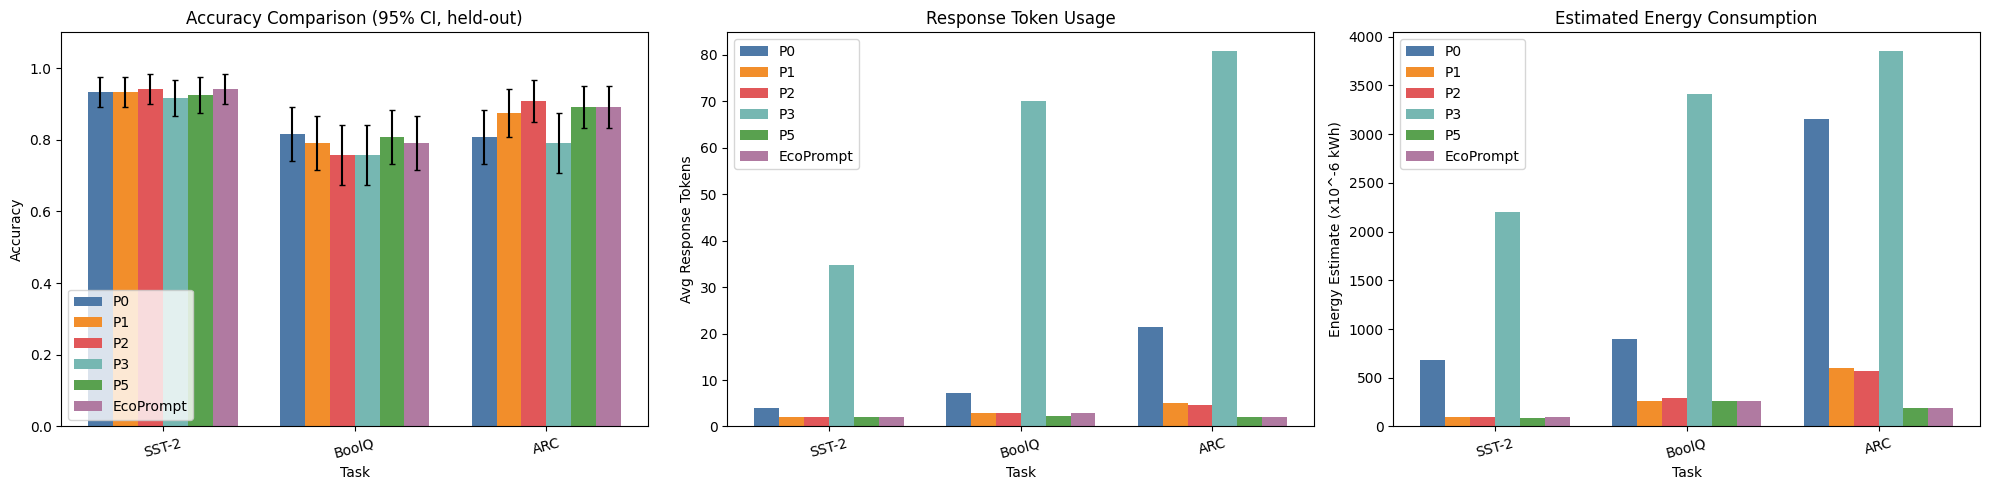

Saved: /kaggle/working/results/accuracy_energy_tradeoff.png


In [24]:

methods = ['P0', 'P1', 'P2', 'P3', 'P5', 'EcoPrompt']
colors = ['#4E79A7', '#F28E2B', '#E15759', '#76B7B2', '#59A14F', '#B07AA1']
x = np.arange(len(data))
width = 0.13

fig, axes = plt.subplots(1, 3, figsize=(20, 5))

ax1 = axes[0]
for i, method in enumerate(methods):
    accs, errs = [], []
    for t in data:
        if method == 'EcoPrompt':
            accs.append(ecoprompt_results[t]['accuracy'])
            lo, hi = bootstrap_ci(ecoprompt_results[t]['correct'])
        else:
            accs.append(test_baseline_results[t][method]['accuracy'])
            lo, hi = bootstrap_ci([int(baseline_predictions[t][method][j] == data[t][j]['a']) for j in test_idx_by_task[t]])
        errs.append(accs[-1] - lo)
    ax1.bar(x + i * width, accs, width, label=method, color=colors[i], yerr=errs, capsize=2)
ax1.set_xlabel('Task'); ax1.set_ylabel('Accuracy')
ax1.set_title('Accuracy Comparison (95% CI, held-out)')
ax1.set_xticks(x + width * 2.5); ax1.set_xticklabels(data.keys(), rotation=15)
ax1.legend(); ax1.set_ylim(0, 1.1)

ax2 = axes[1]
for i, method in enumerate(methods):
    tokens = [ecoprompt_results[t]['avg_response_tokens'] if method == 'EcoPrompt'
              else test_baseline_results[t][method]['avg_response_tokens'] for t in data]
    ax2.bar(x + i * width, tokens, width, label=method, color=colors[i])
ax2.set_xlabel('Task'); ax2.set_ylabel('Avg Response Tokens')
ax2.set_title('Response Token Usage')
ax2.set_xticks(x + width * 2.5); ax2.set_xticklabels(data.keys(), rotation=15)
ax2.legend()

ax3 = axes[2]
for i, method in enumerate(methods):
    energy = [ecoprompt_results[t]['total_energy_kwh'] * 1e6 if method == 'EcoPrompt'
              else test_baseline_results[t][method]['total_energy_kwh'] * 1e6 for t in data]
    ax3.bar(x + i * width, energy, width, label=method, color=colors[i])
ax3.set_xlabel('Task'); ax3.set_ylabel('Energy Estimate (x10^-6 kWh)')
ax3.set_title('Estimated Energy Consumption')
ax3.set_xticks(x + width * 2.5); ax3.set_xticklabels(data.keys(), rotation=15)
ax3.legend()

plt.tight_layout()
plt.savefig(f'{RESULTS_DIR}/accuracy_energy_tradeoff.png', dpi=150, bbox_inches='tight')
plt.show()
print(f"Saved: {RESULTS_DIR}/accuracy_energy_tradeoff.png")


## Cell 23: Strategy Distribution (pie)

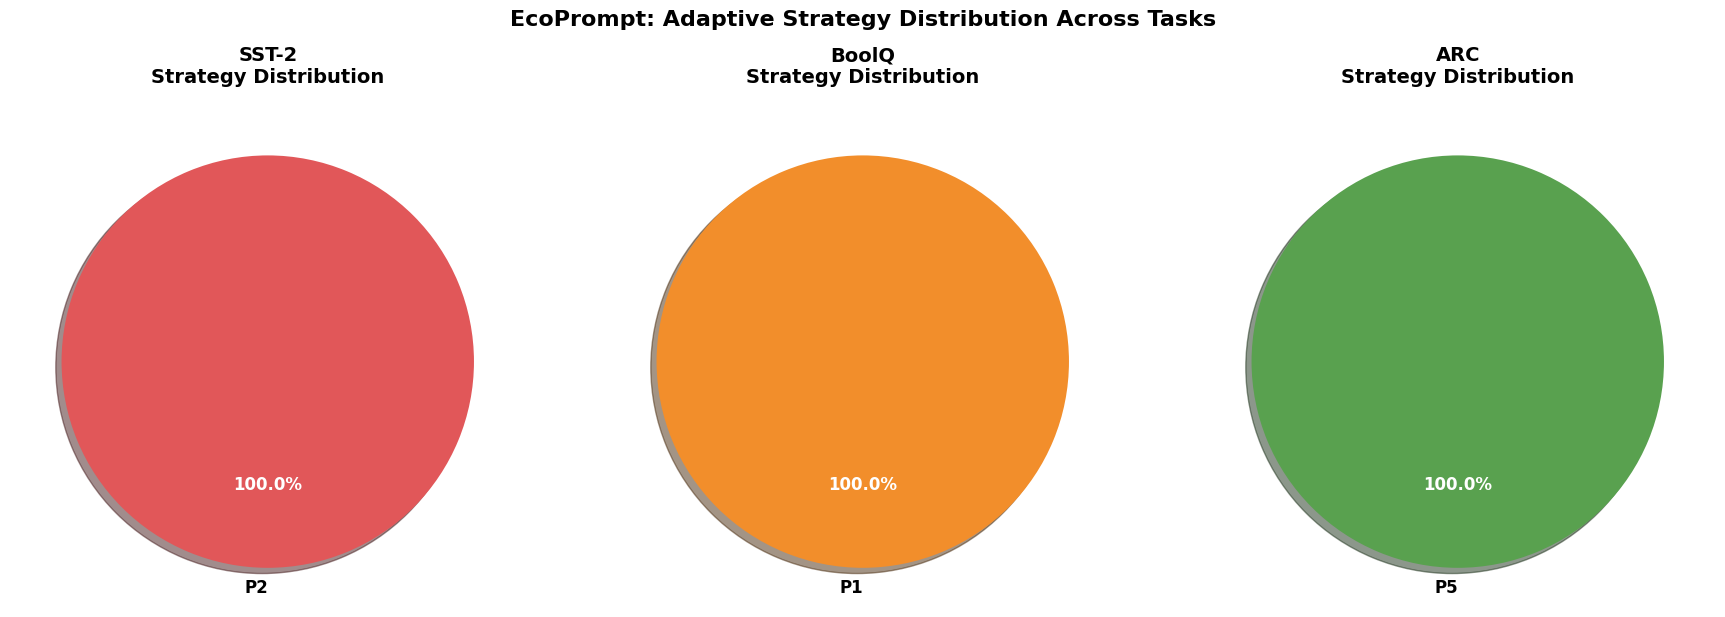

Saved: /kaggle/working/results/strategy_distribution_pie.png


In [25]:
PALETTE = {
    'P0': '#4E79A7', 'P1': '#F28E2B', 'P2': '#E15759',
    'P3': '#76B7B2', 'P5': '#59A14F', 'EcoPrompt': '#B07AA1'
}

fig, axes = plt.subplots(1, len(data), figsize=(18, 6))
for idx, (task_name, records) in enumerate(ecoprompt_raw.items()):
    strategies = [r['strategy'] for r in records]
    counts = Counter(strategies)
    labels = list(counts.keys())
    values = list(counts.values())
    colors = [PALETTE.get(l, '#999999') for l in labels]
    wedges, texts, autotexts = axes[idx].pie(
        values, labels=labels, autopct='%1.1f%%', startangle=90,
        counterclock=False, colors=colors, explode=[0.06] * len(labels),
        shadow=True, textprops={'fontsize': 12, 'weight': 'bold'}
    )
    for autotext in autotexts:
        autotext.set_color('white')
    axes[idx].set_title(f'{task_name}\nStrategy Distribution', fontsize=14, weight='bold')
plt.suptitle('EcoPrompt: Adaptive Strategy Distribution Across Tasks', fontsize=16, weight='bold', y=1.02)
plt.tight_layout()
plt.savefig(f'{RESULTS_DIR}/strategy_distribution_pie.png', dpi=200, bbox_inches='tight', facecolor='white')
plt.show()
print(f'Saved: {RESULTS_DIR}/strategy_distribution_pie.png')

## Cell 24: Feature Importance

Difficulty Router Performance:
  Training samples: 540
  Test samples: 360
  Accuracy: 0.653

Most Important Features:
           feature  importance
      base_logprob    3.287531
   avg_word_length    0.720523
       has_passage    0.541917
num_question_marks    0.503835
      num_newlines    0.361733
  has_math_symbols    0.256603
       has_numbers    0.122057
      token_length    0.011635
       char_length    0.003302


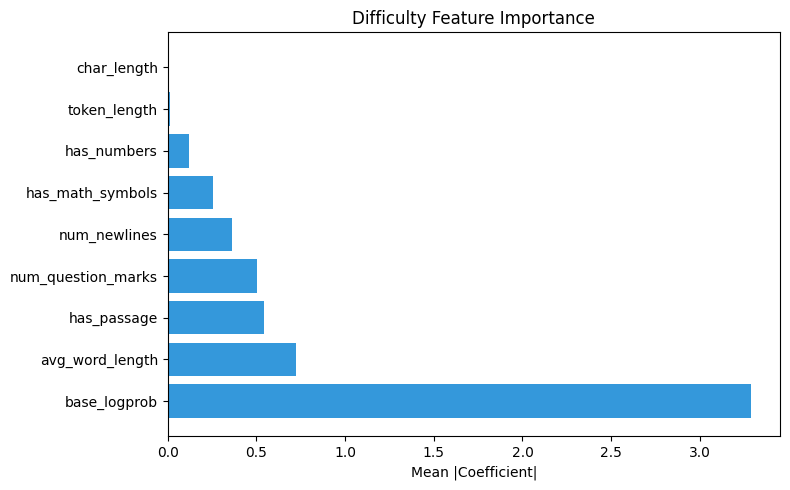

In [26]:
print('Difficulty Router Performance:')
print(f'  Training samples: {len(X_train)}')
print(f'  Test samples: {len(X_test)}')
print(f'  Accuracy: {router_accuracy:.3f}')
print('\nMost Important Features:')
feature_importance = pd.DataFrame({
    'feature': X_all.columns,
    'importance': np.abs(difficulty_clf.coef_).mean(axis=0)
}).sort_values('importance', ascending=False)
print(feature_importance.to_string(index=False))
plt.figure(figsize=(8, 5))
plt.barh(feature_importance['feature'], feature_importance['importance'], color='#3498db')
plt.xlabel('Mean |Coefficient|')
plt.title('Difficulty Feature Importance')
plt.tight_layout()
plt.savefig(f'{RESULTS_DIR}/feature_importance.png', dpi=150)
plt.show()

## Cell 25: Summary

In [27]:

print('=' * 70)
print('ECOPROMPT SUMMARY FOR PAPER (held-out test split)')
print('=' * 70)
total_cot_energy = sum(test_baseline_results[t]['P3']['total_energy_kwh'] for t in data)
total_eco_energy = sum(ecoprompt_results[t]['total_energy_kwh'] for t in data)
total_energy_reduction = (1 - total_eco_energy / total_cot_energy) * 100
avg_cot_acc = np.mean([test_baseline_results[t]['P3']['accuracy'] for t in data])
avg_eco_acc = np.mean([ecoprompt_results[t]['accuracy'] for t in data])
avg_acc_retention = (avg_eco_acc / avg_cot_acc) * 100 if avg_cot_acc > 0 else 0
total_cot_cost = sum(estimate_cost_usd(test_baseline_results[t]['P3']['total_energy_kwh']) for t in data)
total_eco_cost = sum(estimate_cost_usd(ecoprompt_results[t]['total_energy_kwh']) for t in data)
cost_reduction = (1 - total_eco_cost / total_cot_cost) * 100 if total_cot_cost > 0 else 0
avg_bb_acc = np.mean([best_baseline[t]['accuracy'] for t in data])
avg_bb_energy = sum(best_baseline[t]['total_energy_kwh'] for t in data)
print(f'\nOverall Energy Reduction vs Always-CoT: {total_energy_reduction:.1f}%')
print(f'Overall Cost Reduction vs Always-CoT: {cost_reduction:.1f}%')
print(f'Average CoT Accuracy: {avg_cot_acc:.3f}')
print(f'Average EcoPrompt Accuracy: {avg_eco_acc:.3f}')
print(f'Accuracy Retention vs CoT: {avg_acc_retention:.1f}%')
print(f'Average Best-Cheap-Baseline Accuracy: {avg_bb_acc:.3f}')
if avg_bb_energy > 0:
    energy_ratio_bb = total_eco_energy / avg_bb_energy
else:
    energy_ratio_bb = float('inf')
print(f'Energy vs Best-Cheap-Baseline: x{energy_ratio_bb:.2f}')
print(f'\nAverage Escalation Rate: {np.mean([ecoprompt_results[t]["escalation_rate"] for t in data]):.1%}')

summary = {
    'model': MODEL_NAME,
    'num_samples_per_task': NUM_SAMPLES,
    'test_split_fraction': 0.4,
    'total_energy_reduction_vs_cot_pct': round(total_energy_reduction, 2),
    'cost_reduction_vs_cot_pct': round(cost_reduction, 2),
    'avg_accuracy_retention_vs_cot_pct': round(avg_acc_retention, 2),
    'avg_cot_accuracy': round(avg_cot_acc, 4),
    'avg_ecoprompt_accuracy': round(avg_eco_acc, 4),
    'avg_best_cheap_baseline_accuracy': round(avg_bb_acc, 4),
    'router_accuracy': round(router_accuracy, 4),
    'escalation_targets': ESCALATION_TARGET,
    'energy_model': f'GPU TDP {GPU_TDP_W}W + CPU {CPU_TDP_W}W + RAM {RAM_W}W',
    'electricity_price_usd_per_kwh': ELECTRICITY_PRICE_PER_KWH,
}
with open(f'{RESULTS_DIR}/summary.json', 'w') as f:
    json.dump(summary, f, indent=2)
print(f'\nAll results saved to: {RESULTS_DIR}/')

# ---- consolidated diagnostics (used to finalize the paper without rerunning) ----
_tp = sum(1 for a, b in zip(y_test, y_pred) if a == 1 and b == 1)
_fp = sum(1 for a, b in zip(y_test, y_pred) if a == 0 and b == 1)
_fn = sum(1 for a, b in zip(y_test, y_pred) if a == 1 and b == 0)
diagnostics = {
    'model': MODEL_NAME,
    'gpu': GPU_NAME,
    'gpu_tdp_w': GPU_TDP_W,
    'total_power_w': TOTAL_POWER_W,
    'num_samples_per_task': NUM_SAMPLES,
    'batch_size': BATCH_SIZE,
    'max_new_tokens': MAX_NEW_TOKENS,
    'energy_model': f'GPU TDP {GPU_TDP_W}W + CPU {CPU_TDP_W}W + RAM {RAM_W}W',
    'router_accuracy': round(float(router_accuracy), 4),
    'router_hard_precision': round(_tp / (_tp + _fp), 4) if (_tp + _fp) else 0.0,
    'router_hard_recall': round(_tp / (_tp + _fn), 4) if (_tp + _fn) else 0.0,
    'base_strategy': dict(BASE_STRATEGY),
    'escalation_target': dict(ESCALATION_TARGET),
    'router_tau': {k: (None if np.isinf(v) else round(float(v), 6)) for k, v in ROUTER_TAU.items()},
    'per_task': {},
}
for _t in data:
    _task = data[_t][0]['task']
    _base = BASE_STRATEGY[_task]
    _calib = calib_idx_by_task[_t]
    _golds = [ex['a'] for ex in data[_t]]
    _bp = baseline_predictions[_t][_base]
    diagnostics['per_task'][_t] = {
        'base': _base,
        'target': ESCALATION_TARGET[_task],
        'tau': None if np.isinf(ROUTER_TAU[_task]) else round(float(ROUTER_TAU[_task]), 6),
        'calib_base_accuracy': round(float(np.mean([_bp[i] == _golds[i] for i in _calib])), 4),
        'test_accuracy': round(float(ecoprompt_results[_t]['accuracy']), 4),
        'test_escalation_rate': round(float(ecoprompt_results[_t]['escalation_rate']), 4),
        'best_cheap': best_baseline[_t]['strategy'],
        'best_cheap_accuracy': round(float(best_baseline[_t]['accuracy']), 4),
        'test_cot_accuracy': round(float(test_baseline_results[_t]['P3']['accuracy']), 4),
    }
with open(f'{RESULTS_DIR}/diagnostics.json', 'w') as f:
    json.dump(diagnostics, f, indent=2)
print(f"Diagnostics saved: targets={ESCALATION_TARGET} | tau={diagnostics['router_tau']}")


ECOPROMPT SUMMARY FOR PAPER (held-out test split)

Overall Energy Reduction vs Always-CoT: 94.2%
Overall Cost Reduction vs Always-CoT: 94.2%
Average CoT Accuracy: 0.822
Average EcoPrompt Accuracy: 0.875
Accuracy Retention vs CoT: 106.4%
Average Best-Cheap-Baseline Accuracy: 0.889
Energy vs Best-Cheap-Baseline: x0.35

Average Escalation Rate: 0.0%

All results saved to: /kaggle/working/results/
Diagnostics saved: targets={'classification': 'P2', 'factual_qa': 'P3', 'reasoning': 'P5'} | tau={'classification': None, 'factual_qa': None, 'reasoning': None}


## Cell 26: LaTeX Table

In [28]:
latex_table = df_comparison.to_latex(index=False, escape=True)
with open(f'{RESULTS_DIR}/comparison_table.tex', 'w') as f:
    f.write(latex_table)
print(f'LaTeX table saved: {RESULTS_DIR}/comparison_table.tex')

LaTeX table saved: /kaggle/working/results/comparison_table.tex


## Cell 27: Measured GPU Power (sanity check for the energy model)

In [29]:
# Optional sanity check: measure real GPU power draw and compare with the
# TDP-based energy model. Wrapped in try/except so it can never break the run.
try:
    import threading
    import pynvml
    pynvml.nvmlInit()
    _handle = pynvml.nvmlDeviceGetHandleByIndex(0)
    _samples = []
    _stop = {'v': False}

    def _poll():
        while not _stop['v']:
            try:
                _samples.append(pynvml.nvmlDeviceGetPowerUsage(_handle) / 1000.0)
            except Exception:
                pass
            time.sleep(0.05)

    _th = threading.Thread(target=_poll, daemon=True)
    _th.start()
    _t0 = time.time()
    _resps, _, _, _lats, _ = run_batched_strategy(data['ARC'][:16], 'P3', 'reasoning')
    _wall = time.time() - _t0
    _stop['v'] = True
    _th.join(timeout=2)
    pynvml.nvmlShutdown()
    _meas_w = float(np.mean(_samples)) if _samples else float('nan')
    _meas_kwh = _meas_w * _wall / 3600.0 / 1000.0
    _est_kwh = estimate_energy_kwh(float(np.sum(_lats)))
    print(f'Measured GPU power: {_meas_w:.1f} W over {_wall:.1f} s')
    print(f'Measured energy: {_meas_kwh:.6f} kWh | TDP-model energy: {_est_kwh:.6f} kWh | ratio {_meas_kwh/_est_kwh:.2f}')
    with open(f'{RESULTS_DIR}/power_validation.json', 'w') as f:
        json.dump({'measured_w': _meas_w, 'measured_kwh': _meas_kwh,
                   'model_kwh': _est_kwh, 'wall_s': _wall,
                   'model_total_w': TOTAL_POWER_W}, f, indent=2)
except Exception as exc:
    print(f'Power validation skipped: {type(exc).__name__}: {exc}')

import glob
print('\nResult files written:')
for _f in sorted(glob.glob(f'{RESULTS_DIR}/*.json')):
    print(f'  {os.path.basename(_f):28s} {os.path.getsize(_f):>8d} bytes')


Measured GPU power: 37.5 W over 13.1 s
Measured energy: 0.000136 kWh | TDP-model energy: 0.000525 kWh | ratio 0.26

Result files written:
  ablation_results.json           52743 bytes
  baseline_results.json          105744 bytes
  best_baseline.json                489 bytes
  diagnostics.json                 1496 bytes
  ecoprompt_raw.json             184618 bytes
  ecoprompt_results.json           4154 bytes
  power_validation.json             173 bytes
  router_ablation.json             7743 bytes
  routing_config.json               197 bytes
  summary.json                      574 bytes
  test_baseline_results.json       2256 bytes
